In [ ]:
from utils.library import *
from utils.download import *
from utils.metrics import split_temporal
from utils.stock_config import *
from models.arima import *
from models.xgboost import run_xgboost, run_xgboost_30
from models.lstm import run_lstm, run_lstm_30
from utils.plots import plot_forecast, plot_forecast_30
from models.shap import explain_variables

c:\TCC\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Buscando dados

In [2]:
vale_csv = "data/vale.csv"

if not os.path.exists(vale_csv):
    vale3_dataset = load_stock(STOCKS["vale"], "vale", force=True)
    vale3_dataset.head(10)

vale3_dataset = pd.read_csv(vale_csv)

In [3]:
vale3_dataset

,date,vale_close,vale_high,vale_low,vale_open,vale_volume,ibovespa,vix,selic_daily,selic_goal,ipca,fx_usd,gdp,unemployment
0,2012-03-01,17.508444,17.627684,17.337533,17.397153,2644500,66810.0,17.260000,0.039270,10.5,0.21,1.7152,397757.8,8.0
1,2012-03-02,17.667425,17.711147,17.448818,17.536260,3089900,67782.0,17.290001,0.039270,10.5,0.21,1.7245,397757.8,8.0
2,2012-03-05,17.150721,17.528313,17.003657,17.512416,4268900,66964.0,18.049999,0.039270,10.5,0.21,1.7314,397757.8,8.0
3,2012-03-06,16.320017,16.685686,16.180902,16.645940,8037500,65114.0,20.870001,0.039270,10.5,0.21,1.7556,397757.8,8.0
4,2012-03-07,16.296165,16.375659,15.962293,16.375659,7283600,66017.0,19.070000,0.039270,10.5,0.21,1.7692,397757.8,8.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3434,2025-12-22,70.929672,71.367394,68.877263,69.091260,27853000,158142.0,14.080000,0.055131,15.0,0.33,5.5389,1084318.8,5.1
3435,2025-12-23,70.910225,71.523027,70.598959,71.231219,17140900,160456.0,14.000000,0.055131,15.0,0.33,5.5643,1084318.8,5.1
3436,2025-12-26,71.124222,71.347940,70.637869,70.871316,16368800,160897.0,13.600000,0.055131,15.0,0.33,5.5413,1084318.8,5.1
3437,2025-12-29,70.151512,71.727290,69.742970,71.192307,19963700,160490.0,14.200000,0.055131,15.0,0.33,5.5739,1084318.8,5.1


In [4]:
print(vale3_dataset.isna().sum())

date            0
vale_close      0
vale_high       0
vale_low        0
vale_open       0
vale_volume     0
ibovespa        0
vix             0
selic_daily     0
selic_goal      0
ipca            0
fx_usd          0
gdp             0
unemployment    0
dtype: int64


## ARIMA

--- Identificando ordem do ARIMA para VALE ---
Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=5970.913, Time=0.71 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=5967.702, Time=0.13 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=5969.683, Time=0.06 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=5969.682, Time=0.11 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=5966.962, Time=0.03 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=5971.683, Time=0.11 sec

Best model:  ARIMA(0,1,0)(0,0,0)[0]          
Total fit time: 1.180 seconds
Ordem ARIMA selecionada: (0, 1, 0)
ARIMA(0, 1, 0) vale    RMSE: 0.7749 | MAE: 0.5739 | MAPE: 1.11% | Acurácia direcional: n/a


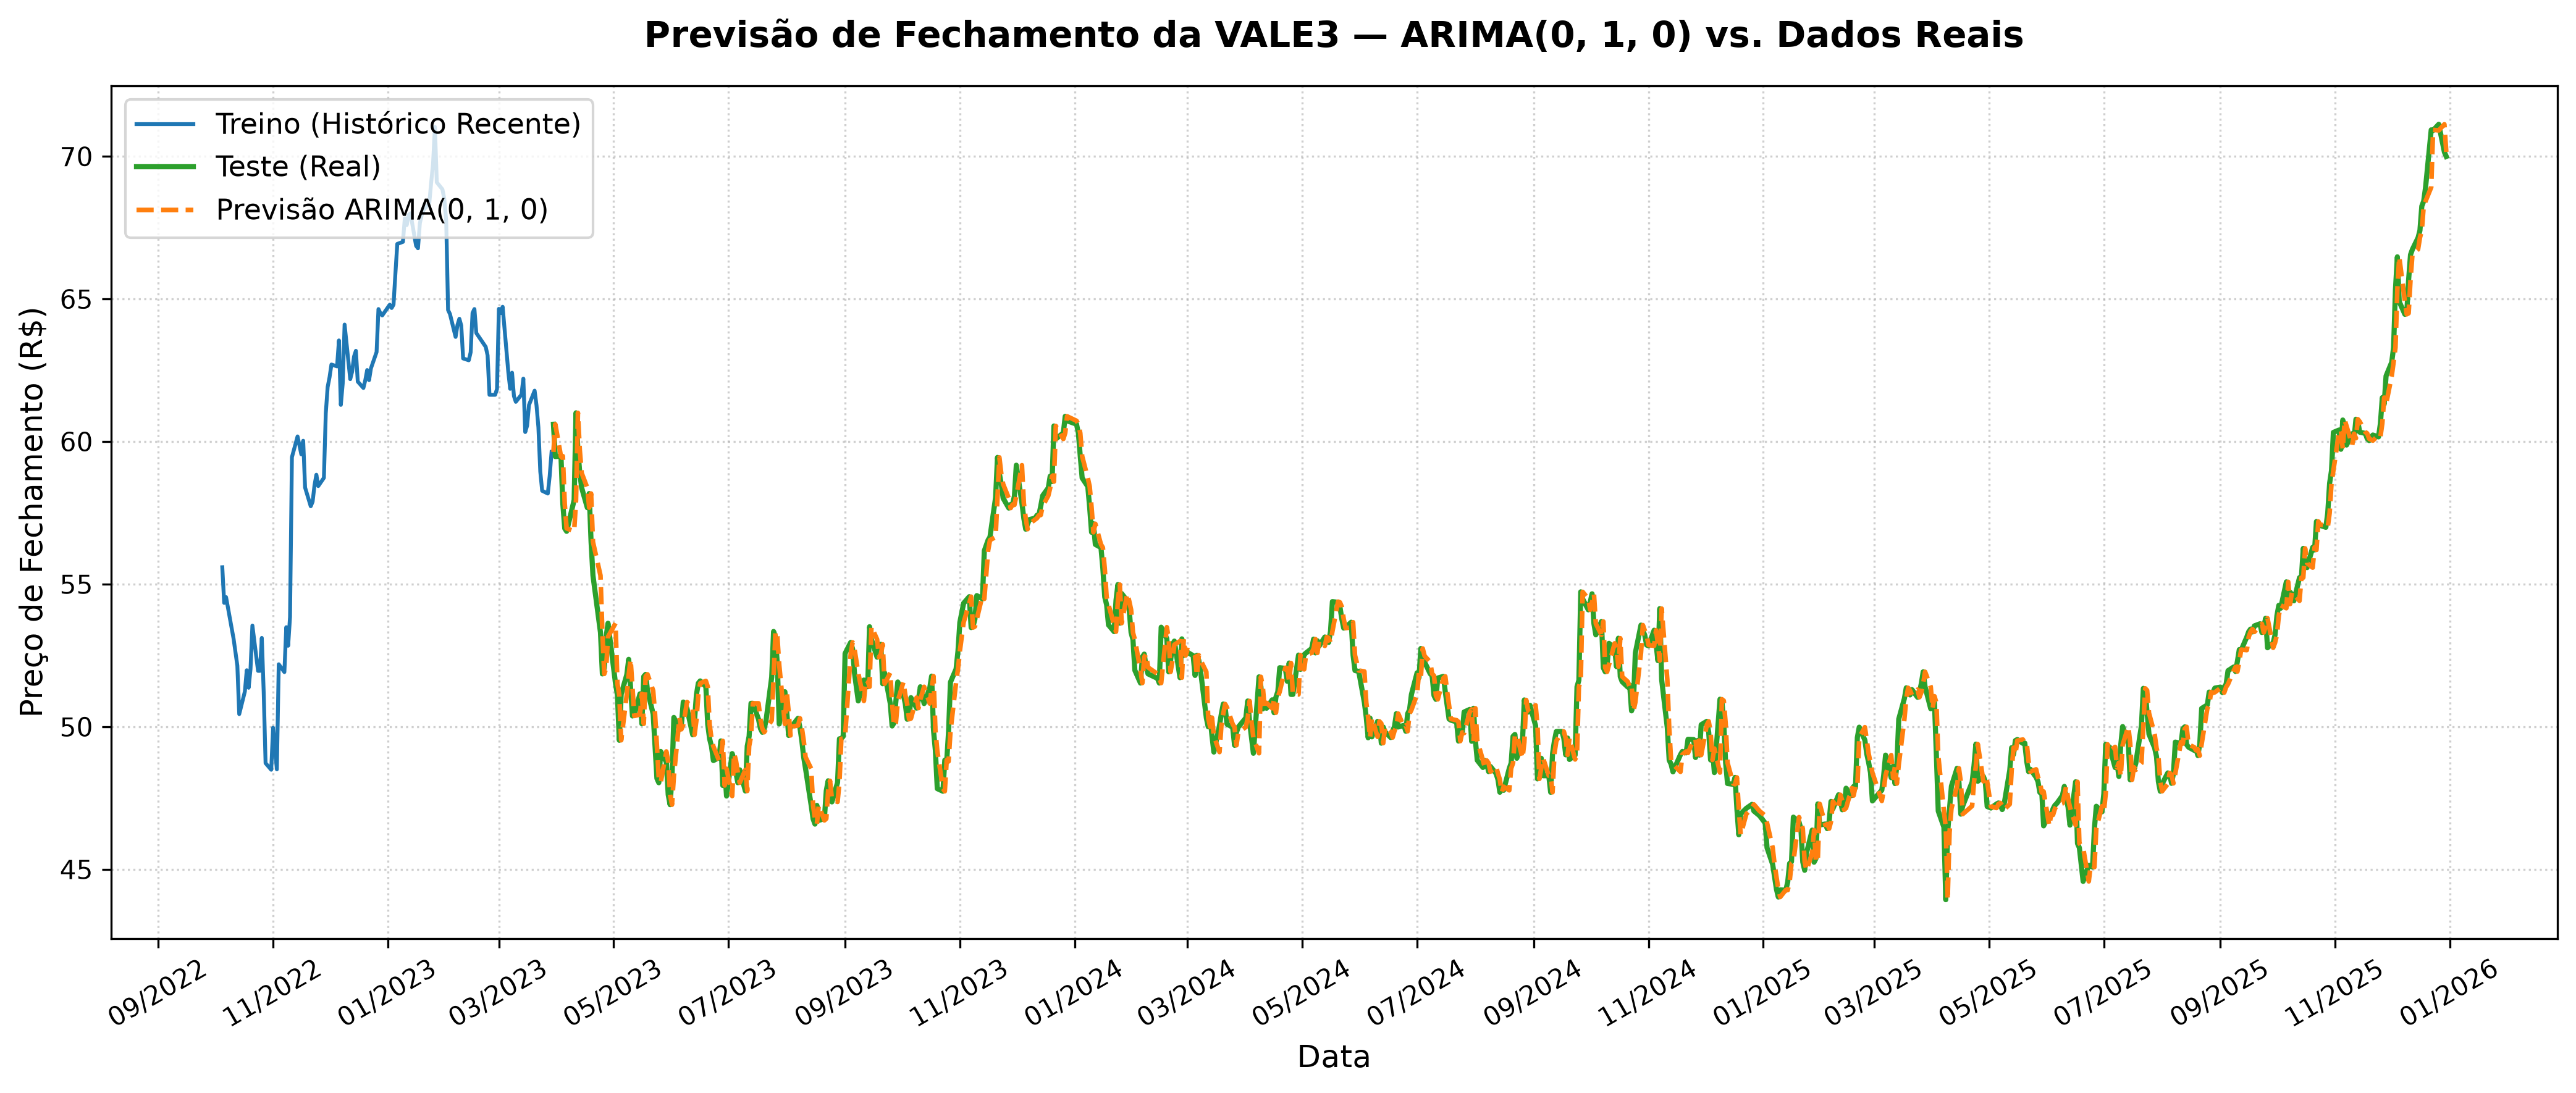

In [5]:
train_vale, test_vale = split_temporal(vale3_dataset)
res_vale = run_arima(train_vale, test_vale, "vale")
plot_forecast(
    train_vale, test_vale,
    predictions=res_vale["predictions"],
    stock_name="vale",
    model_name=f"ARIMA{res_vale['order']}",
    ticker_label="VALE3",
)

ARIMA(0, 1, 0) | horizonte = 30 dias
ARIMA(0, 1, 0) vale h=30 RMSE: 3.9712 | MAE: 3.1899 | MAPE: 6.05% | Acurácia direcional: n/a
dict_keys(['stock', 'order', 'horizon', 'model', 'backtest', 'futuro', 'path', 'path_ci', 'real_path', 'predictions', 'real', 'baseline', 'rmse', 'mae', 'mape', 'dir_acc'])


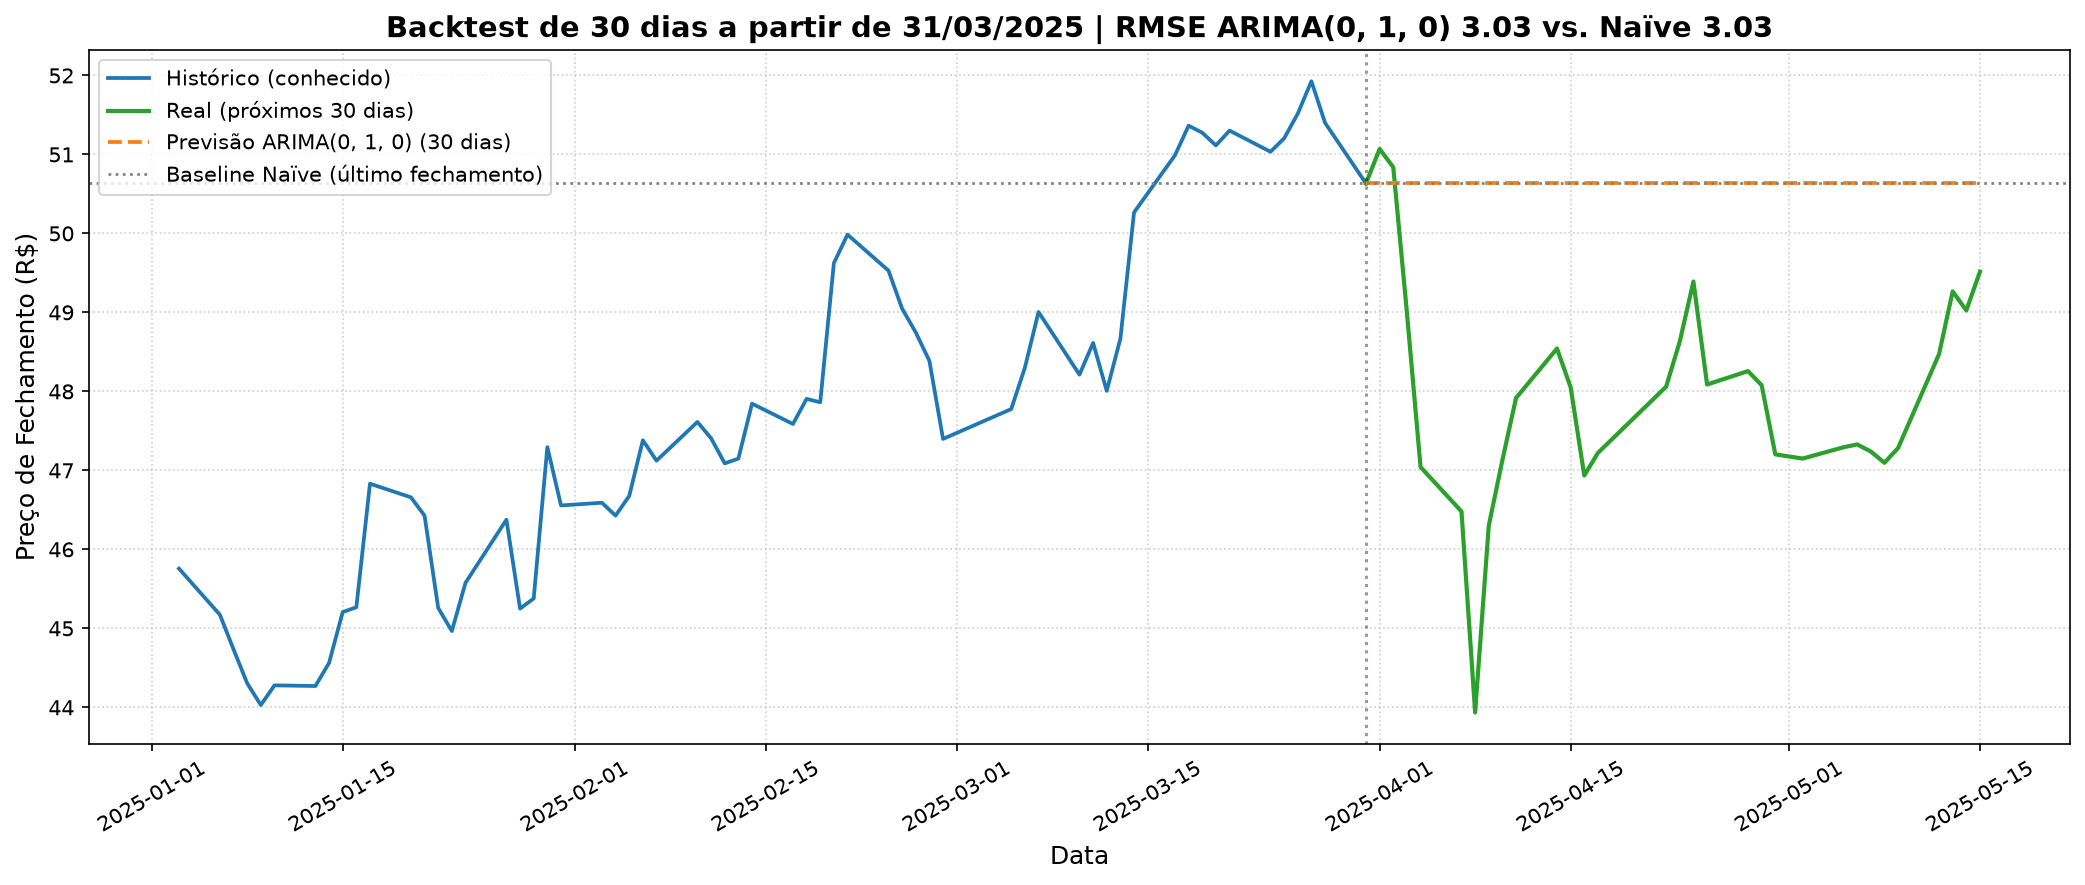

In [6]:
res_vale_30 = run_arima_30(train_vale, test_vale, "vale", horizon=30)
print(res_vale_30.keys())   # deve listar 'backtest' e 'futuro'

plot_forecast_30(res_vale_30, train_vale, test_vale, "vale", origem="2025-03-31",
                 model_name=f"ARIMA{res_vale_30['order']}")

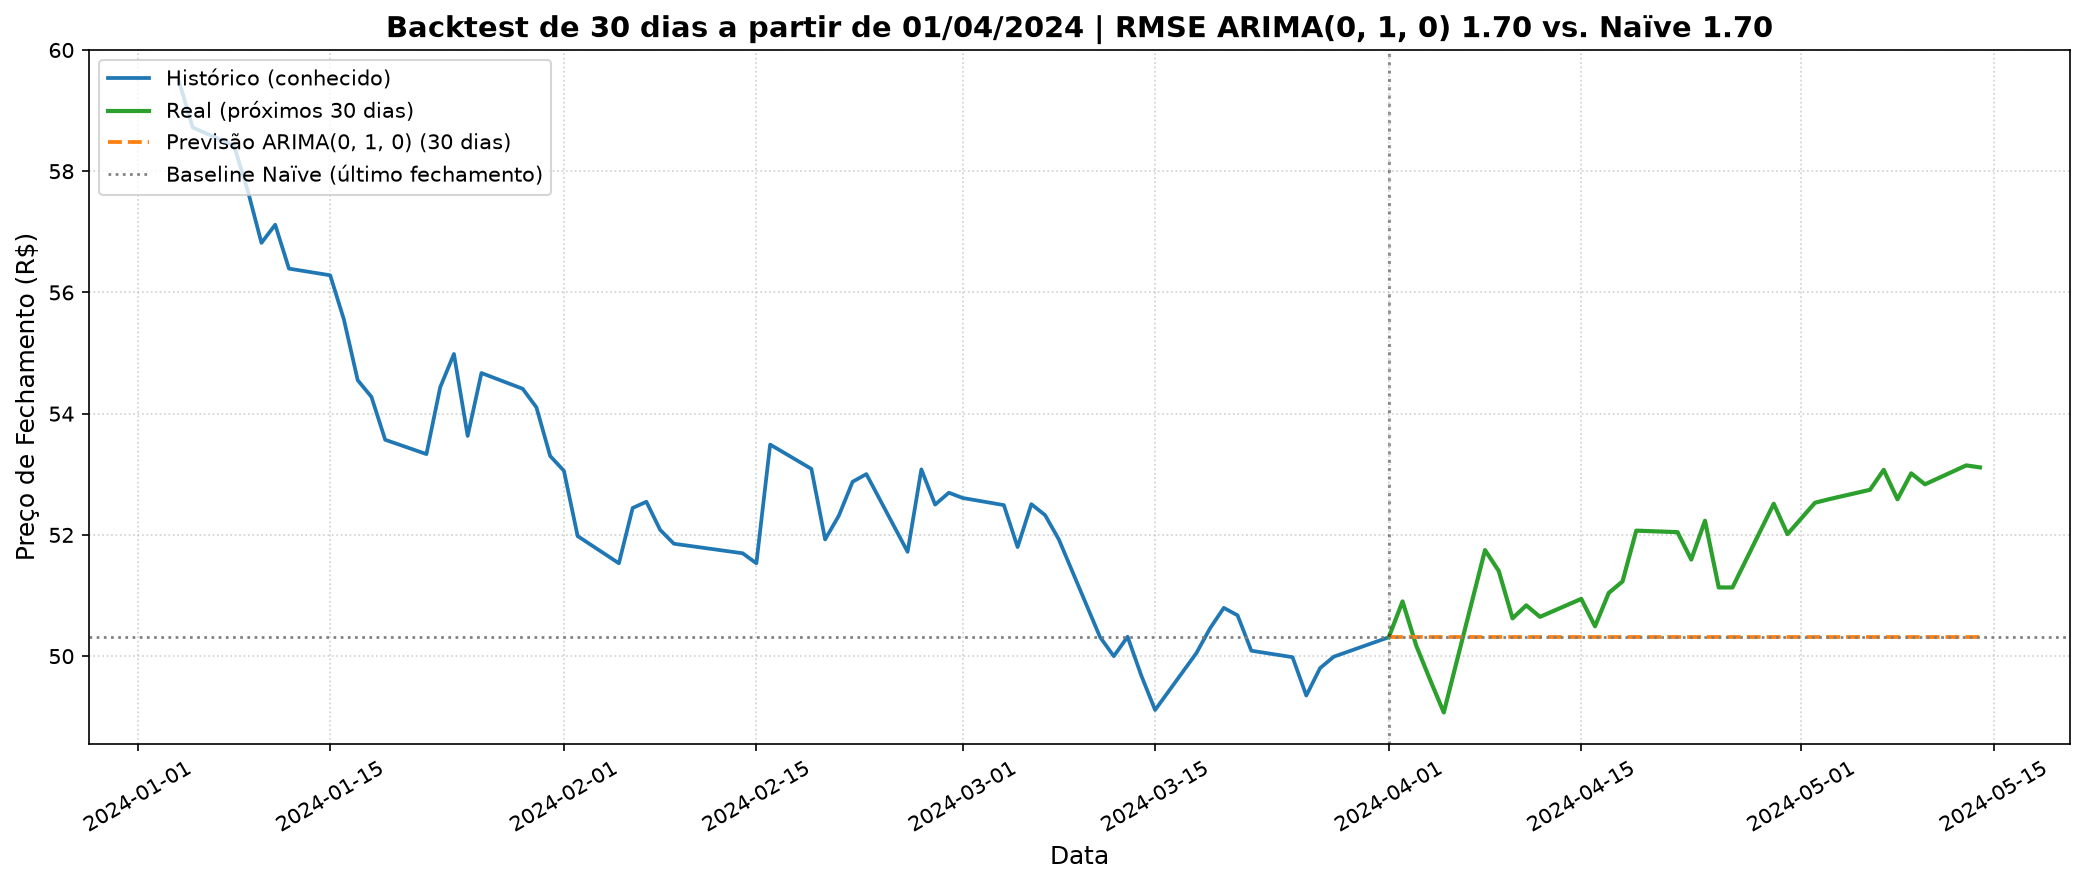

In [13]:
plot_forecast_30(res_vale_30, train_vale, test_vale, "vale", origem="2024-03-31",
                 model_name=f"ARIMA{res_vale_30['order']}")

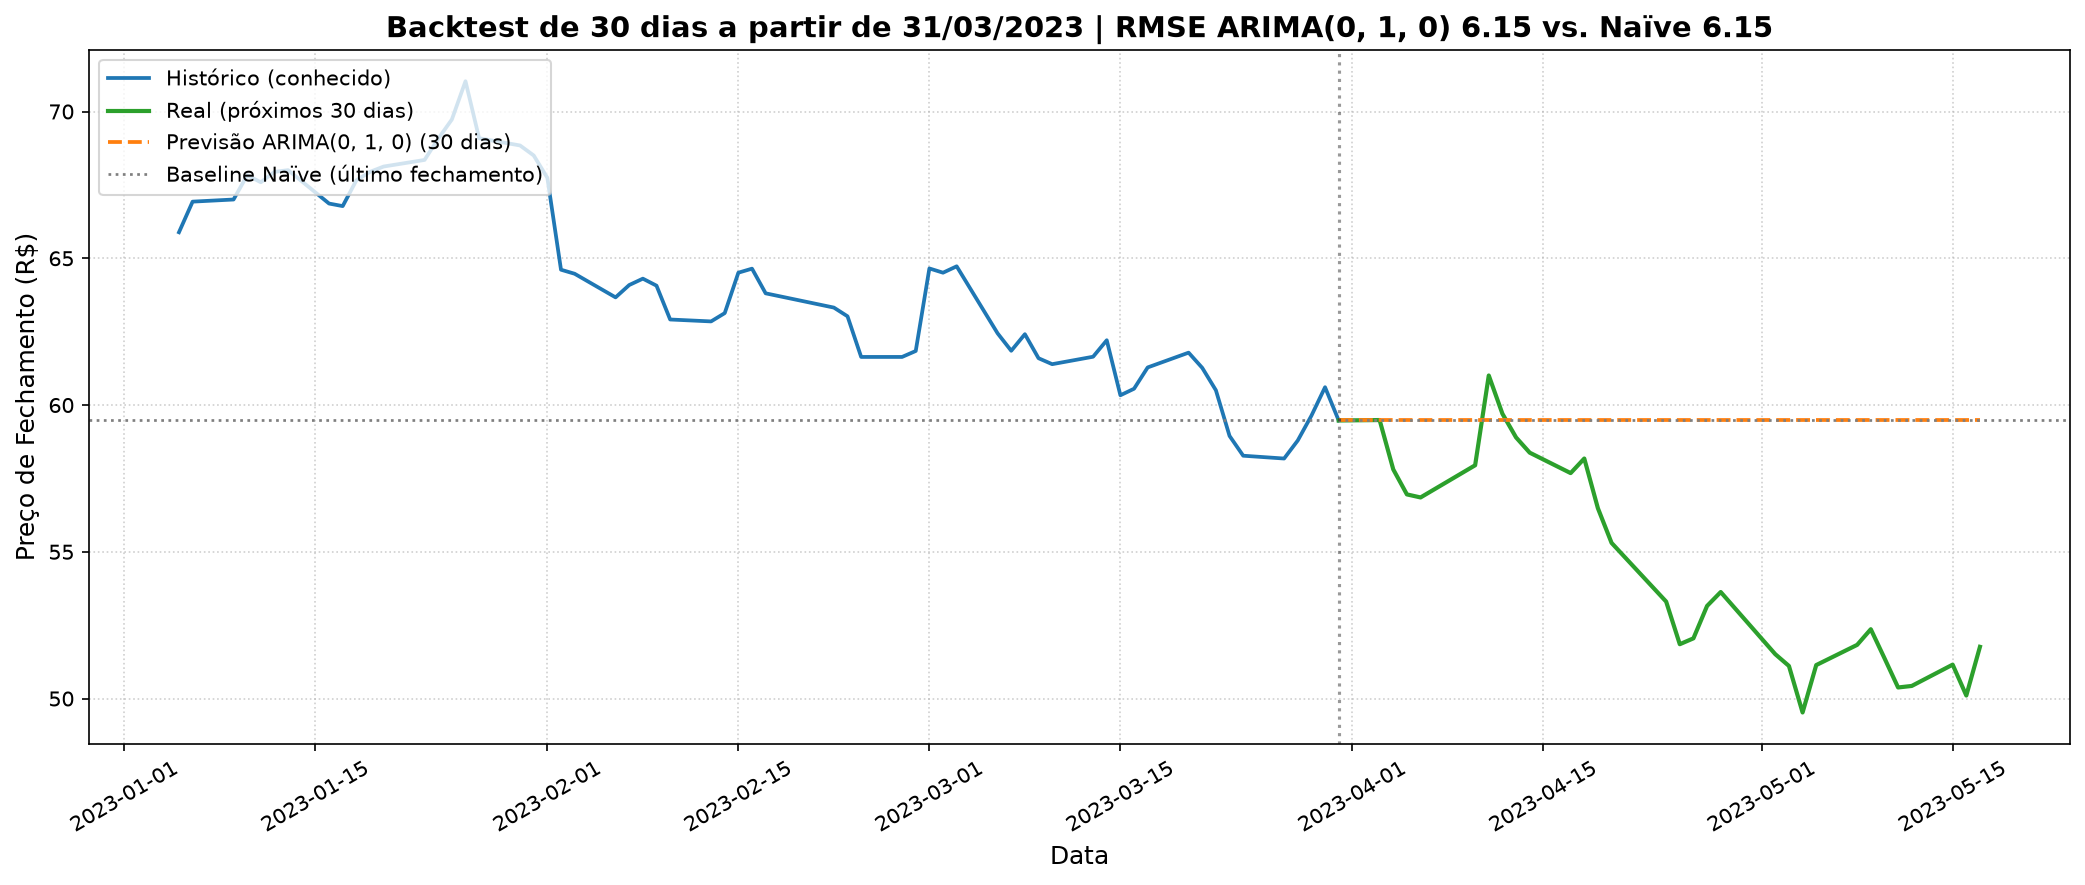

In [14]:
plot_forecast_30(res_vale_30, train_vale, test_vale, "vale", origem="2023-03-31",
                 model_name=f"ARIMA{res_vale_30['order']}")

## XGBooster

--- XGBoost VALE: 37 features, 2748 treino / 688 teste ---
Fitting 5 folds for each of 54 candidates, totalling 270 fits
Melhores hiperparâmetros: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100, 'subsample': 1.0}
Melhor RMSE médio (validação): 5.3444
XGBoost vale           RMSE: 0.9102 | MAE: 0.7299 | MAPE: 1.43% | Acurácia direcional: 57.85%
Naive vale             RMSE: 0.7749 | MAE: 0.5739 | MAPE: 1.11% | Acurácia direcional: n/a
p-valor (teste binomial, acurácia direcional): 0.0000


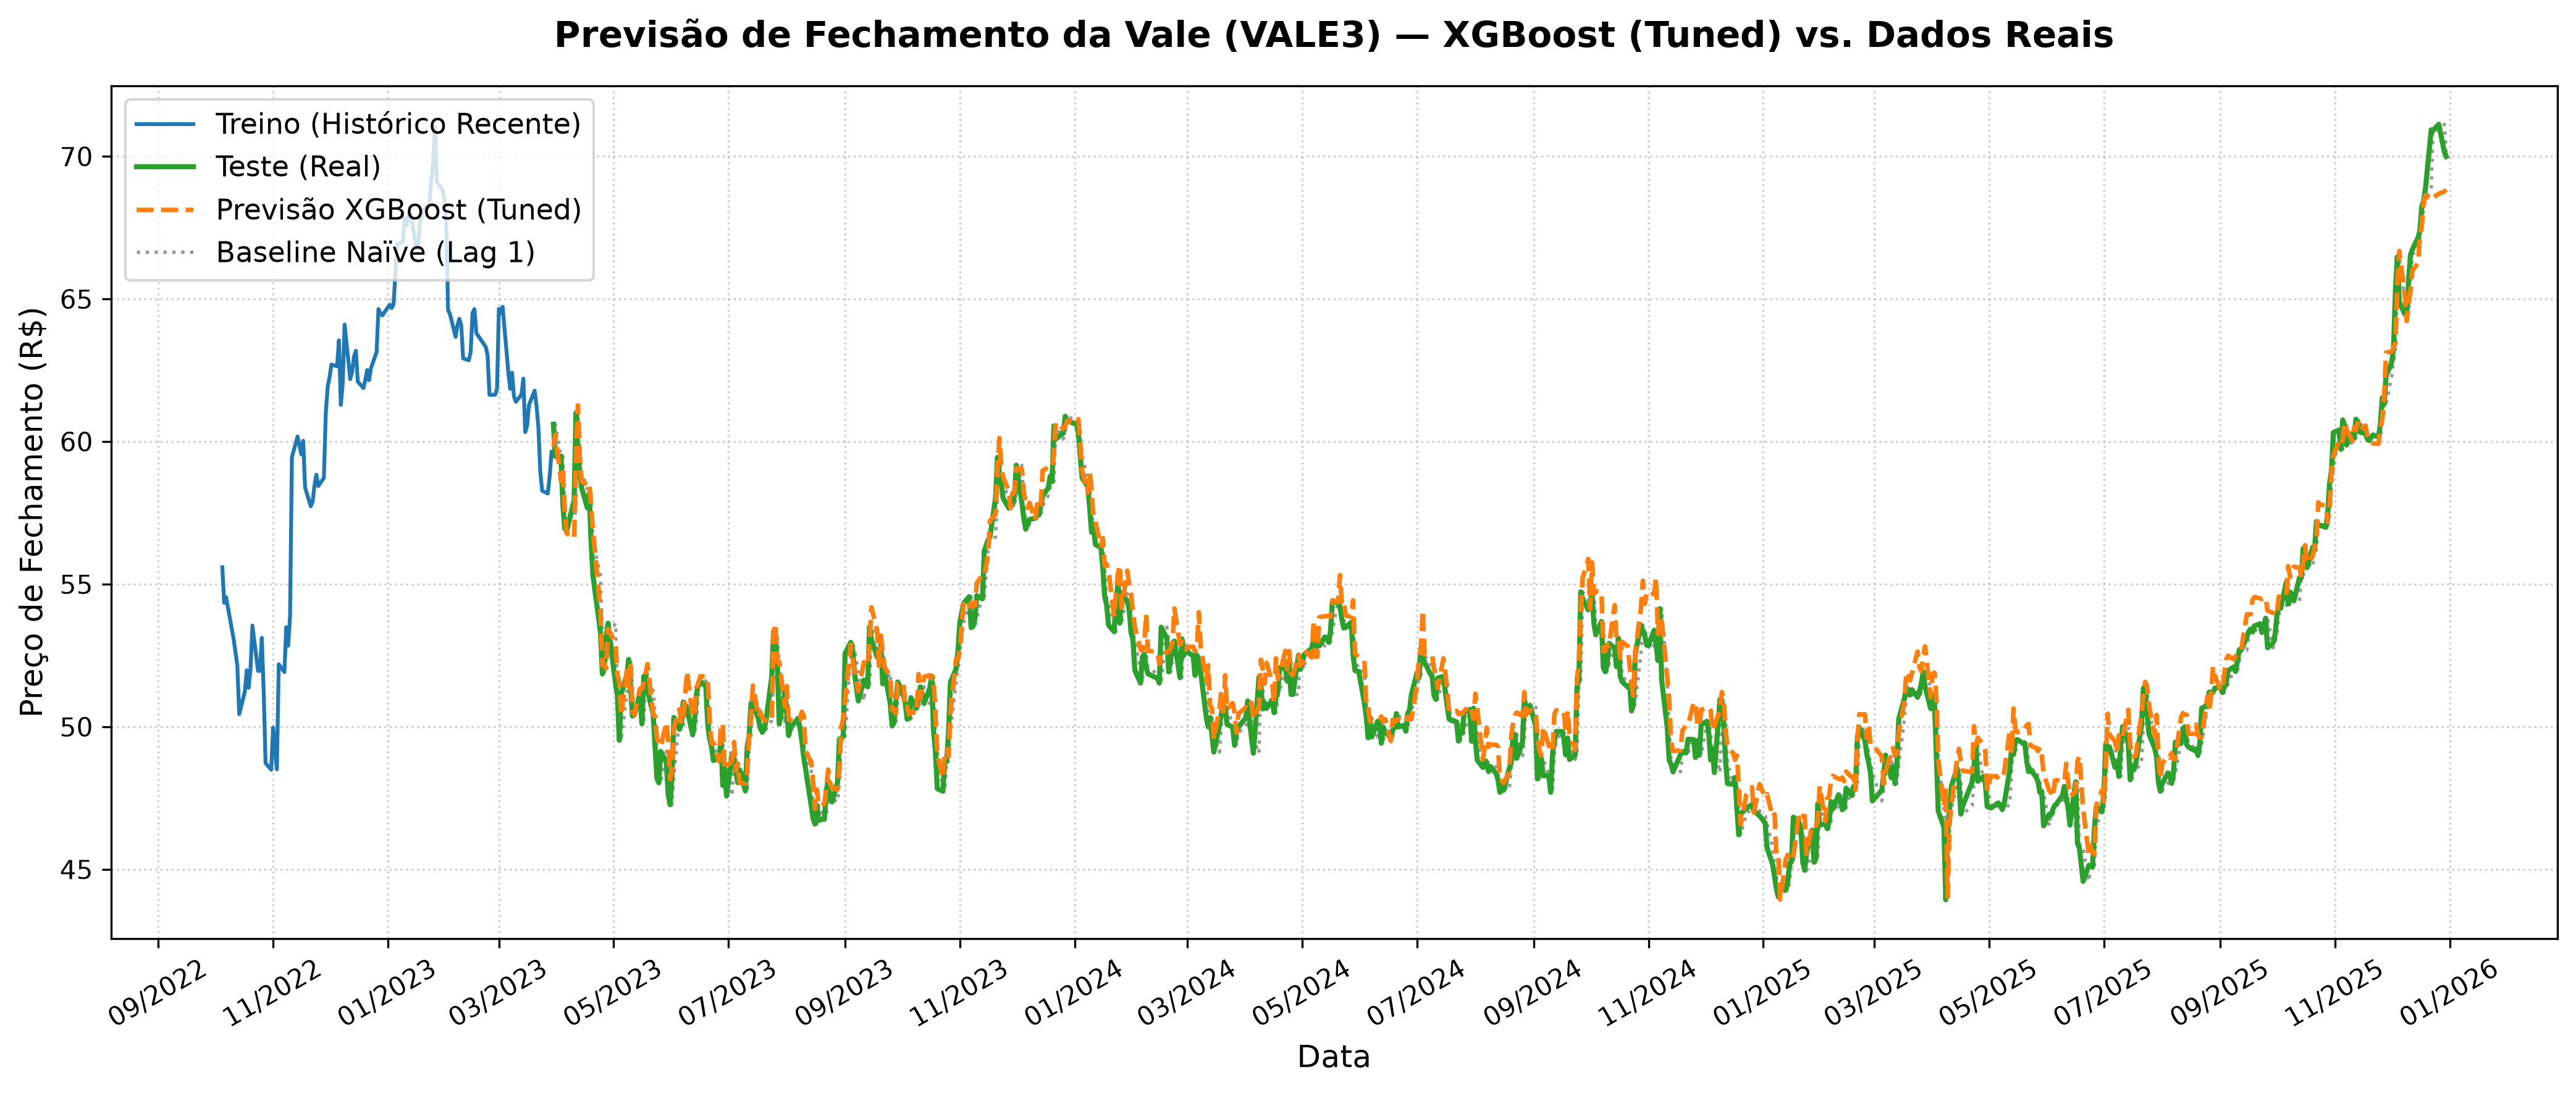

In [ ]:
res_xgbooster = run_xgboost(train_vale, test_vale, "vale")
plot_forecast(
    train_vale, test_vale,
    predictions=res_xgbooster["predictions"],
    stock_name="vale",
    model_name="XGBoost (Tuned)",
    ticker_label="VALE3",
    company_name="Vale",
    baseline=res_xgbooster["ontem"],        # baseline naive (preço de ontem)
)

In [ ]:
res_vale_30 = run_xgboost_30(train_vale, test_vale, "vale", horizon=30)
print(res_vale_30["rmse"], res_vale_30["naive_rmse"], res_vale_30["dir_acc"], res_vale_30["dir_pvalue"])

plot_forecast_30(res_vale_30, train_vale, test_vale, "vale", origem="2025-03-31", model_name="XGBoost")
plot_forecast_30(res_vale_30, train_vale, test_vale, "vale", model_name="XGBoost")   # futuro

## LSTM

Keras backend: torch | dispositivo: NVIDIA GeForce RTX 3050 6GB Laptop GPU
--- LSTM VALE: treino (2318, 20, 13), val (413, 20, 13), teste (688, 20, 13) ---
Reloading Tuner from lstm_tuning\vale_lstm\tuner0.json
Melhores hiperparâmetros: {'n_layers': 1, 'units_0': 128, 'dropout_0': 0.4, 'learning_rate': 0.001, 'units_1': 128, 'dropout_1': 0.2, 'units_2': 32, 'dropout_2': 0.0, 'tuner/epochs': 4, 'tuner/initial_epoch': 2, 'tuner/bracket': 2, 'tuner/round': 1, 'tuner/trial_id': '0003'}
Epoch 1/100
11/37 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0294 - mae: 0.1328  

c:\TCC\venv\Lib\site-packages\keras\src\backend\torch\rnn.py:656: UserWarning: RNN module weights are not part of single contiguous chunk of memory. This means they need to be compacted at every call, possibly greatly increasing memory usage. To compact weights again call flatten_parameters(). (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\native\cudnn\RNN.cpp:1481.)
  outputs, h_n, c_n = torch._VF.lstm(


37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0151 - mae: 0.0905 - val_loss: 0.0175 - val_mae: 0.1233
Epoch 2/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0050 - mae: 0.0535 - val_loss: 0.0025 - val_mae: 0.0400
Epoch 3/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0030 - mae: 0.0415 - val_loss: 0.0024 - val_mae: 0.0395
Epoch 4/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0025 - mae: 0.0370 - val_loss: 0.0032 - val_mae: 0.0466
Epoch 5/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0018 - mae: 0.0318 - val_loss: 0.0040 - val_mae: 0.0530
Epoch 6/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0019 - mae: 0.0326 - val_loss: 0.0037 - val_mae: 0.0505
Epoch 7/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0014 - mae: 0.0278 - val_loss: 0.0030 - val_mae: 0.0455
Epoch 8/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0014 - mae: 0.0270 - val_loss: 0.0055 - val_mae: 0.0637
LSTM vale              RMSE: 1.8357 | MAE: 1.4387 | MAPE: 2.73% | Acurácia d

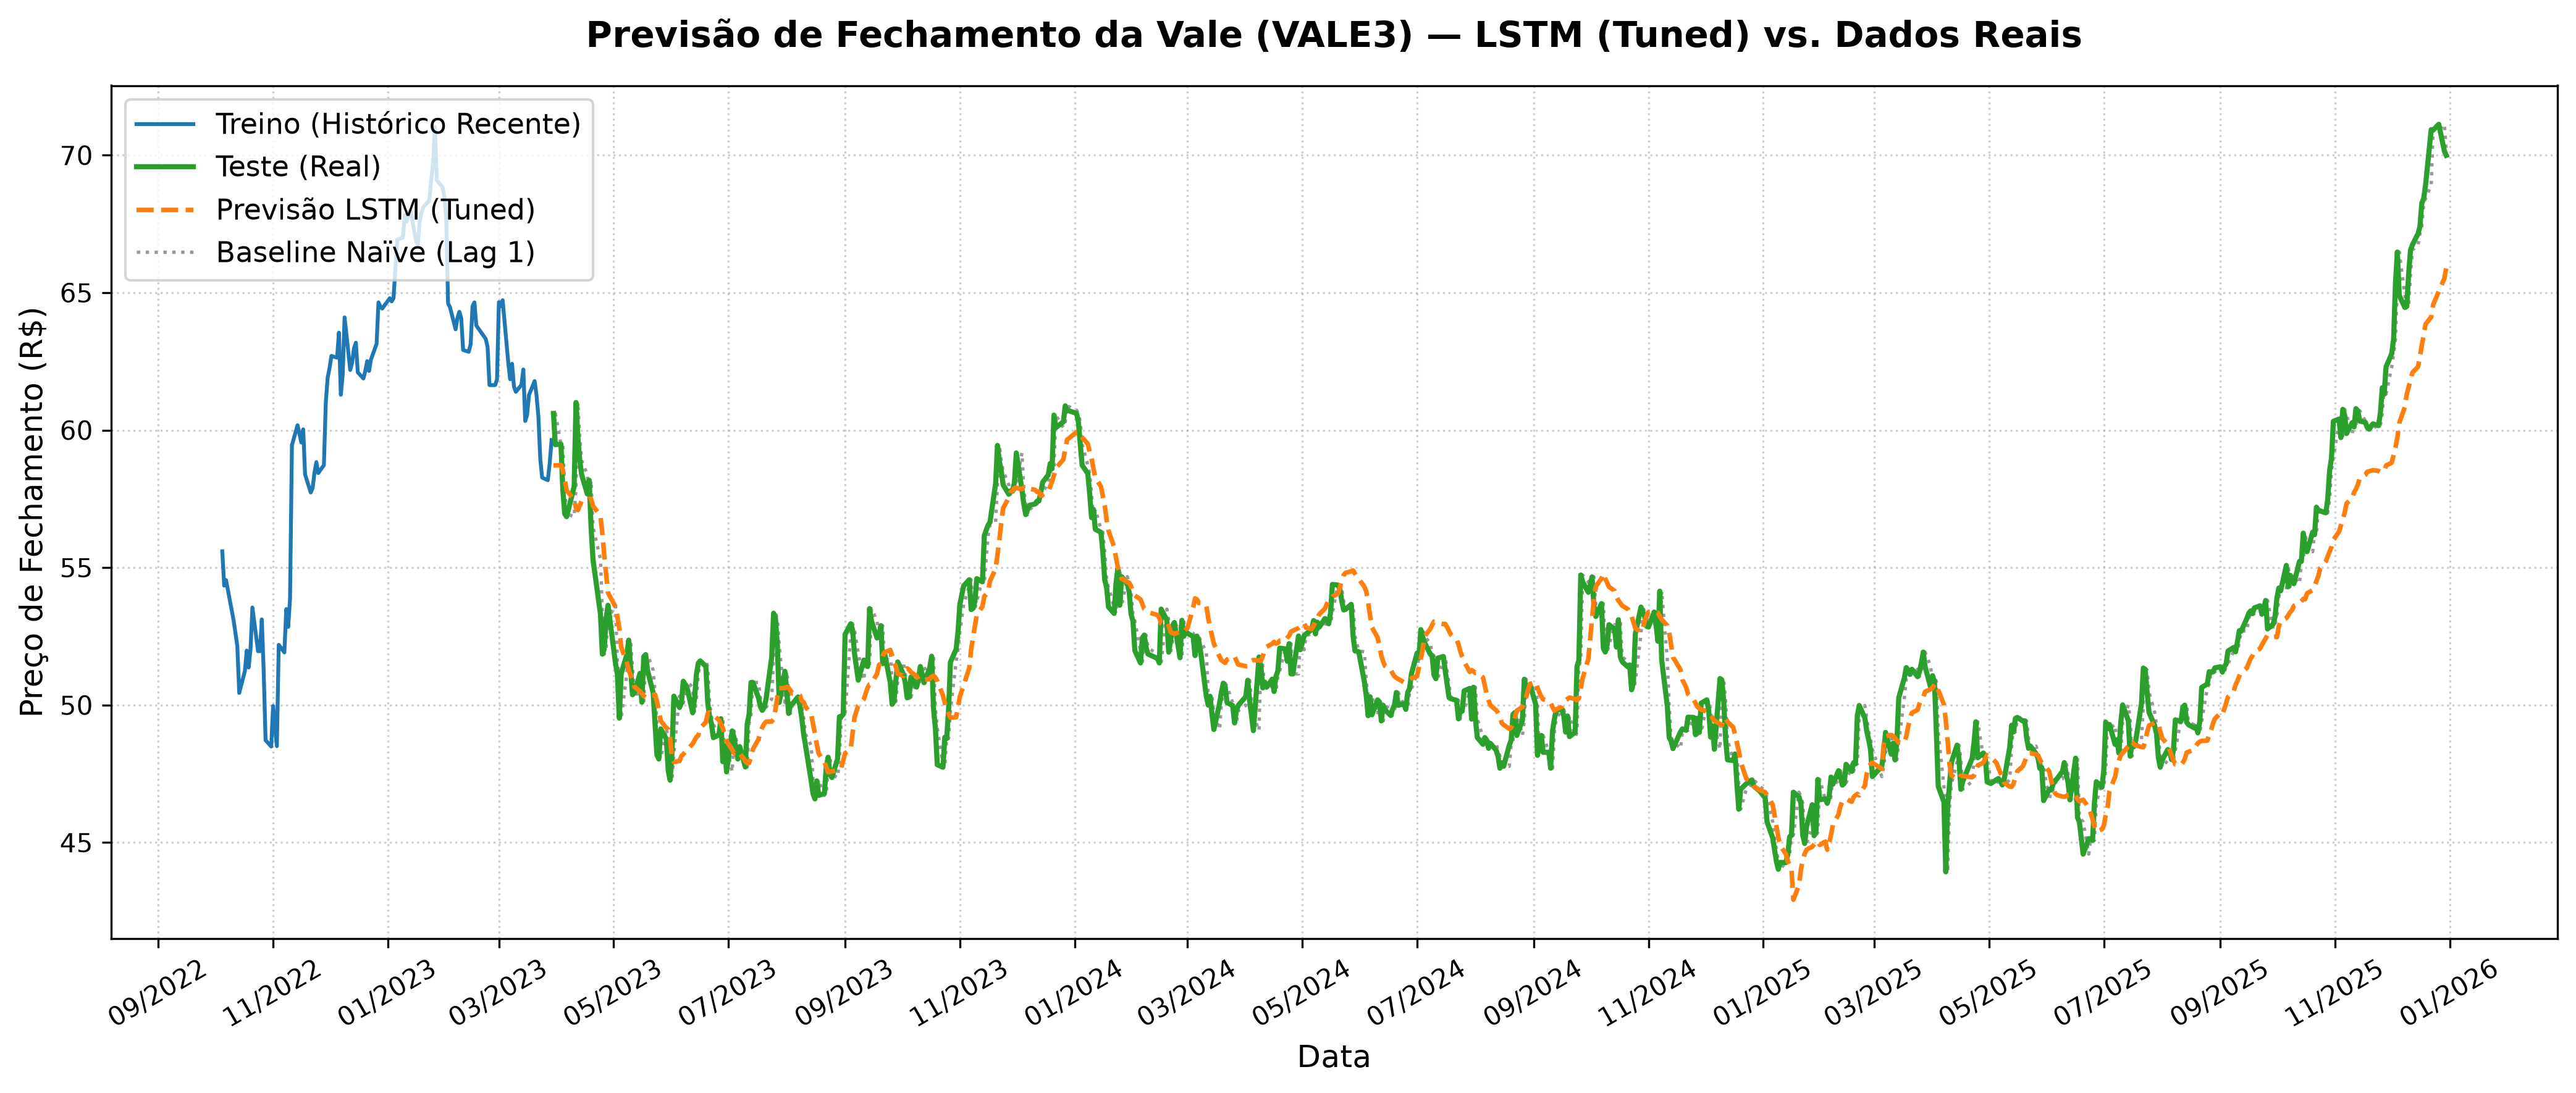

In [8]:
res_lstm = run_lstm(train_vale, test_vale, "vale", max_epochs=10)
plot_forecast(train_vale, test_vale, res_lstm["predictions"], "vale",
              model_name="LSTM (Tuned)", ticker_label="VALE3",
              company_name="Vale", baseline=res_lstm["ontem"])

In [9]:
res_lstm_30 = run_lstm_30(train_vale, test_vale, "vale", res_lstm["best_params"])

Epoch 1/100
29/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0370

c:\TCC\venv\Lib\site-packages\keras\src\backend\torch\rnn.py:656: UserWarning: RNN module weights are not part of single contiguous chunk of memory. This means they need to be compacted at every call, possibly greatly increasing memory usage. To compact weights again call flatten_parameters(). (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\native\cudnn\RNN.cpp:1481.)
  outputs, h_n, c_n = torch._VF.lstm(


36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0320 - val_loss: 0.0354
Epoch 2/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0079 - val_loss: 0.0283
Epoch 3/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0055 - val_loss: 0.0296
Epoch 4/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0044 - val_loss: 0.0222
Epoch 5/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0037 - val_loss: 0.0294
Epoch 6/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0035 - val_loss: 0.0247
Epoch 7/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0031 - val_loss: 0.0260
Epoch 8/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0027 - val_loss: 0.0231
Epoch 9/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0027 - val_loss: 0.0190
Epoch 10/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0024 - val_loss: 0.0227
Epoch 11/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0024 - val_loss: 0.0169
Epoch 12/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0022 - val_lo

c:\TCC\venv\Lib\site-packages\keras\src\backend\torch\rnn.py:656: UserWarning: RNN module weights are not part of single contiguous chunk of memory. This means they need to be compacted at every call, possibly greatly increasing memory usage. To compact weights again call flatten_parameters(). (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\native\cudnn\RNN.cpp:1481.)
  outputs, h_n, c_n = torch._VF.lstm(
c:\TCC\venv\Lib\site-packages\keras\src\backend\torch\rnn.py:656: UserWarning: RNN module weights are not part of single contiguous chunk of memory. This means they need to be compacted at every call, possibly greatly increasing memory usage. To compact weights again call flatten_parameters(). (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\native\cudnn\RNN.cpp:1481.)
  outputs, h_n, c_n = torch._VF.lstm(
c:\TCC\venv\Lib\site-packages\keras\src\backend\torch\rnn.py:656: UserWarning: RNN module weights are not part of single

Epoch 1/100
 1/36 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.1656

c:\TCC\venv\Lib\site-packages\keras\src\backend\torch\rnn.py:656: UserWarning: RNN module weights are not part of single contiguous chunk of memory. This means they need to be compacted at every call, possibly greatly increasing memory usage. To compact weights again call flatten_parameters(). (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\native\cudnn\RNN.cpp:1481.)
  outputs, h_n, c_n = torch._VF.lstm(


36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0320 - val_loss: 0.0354
Epoch 2/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0079 - val_loss: 0.0283
Epoch 3/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0055 - val_loss: 0.0296
Epoch 4/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0044 - val_loss: 0.0222
Epoch 5/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0037 - val_loss: 0.0294
Epoch 6/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0035 - val_loss: 0.0247
Epoch 7/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0031 - val_loss: 0.0260
Epoch 8/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0027 - val_loss: 0.0231
Epoch 9/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0027 - val_loss: 0.0190
Epoch 10/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0024 - val_loss: 0.0227
Epoch 11/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0024 - val_loss: 0.0169
Epoch 12/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0022 - val_lo

c:\TCC\venv\Lib\site-packages\keras\src\backend\torch\rnn.py:656: UserWarning: RNN module weights are not part of single contiguous chunk of memory. This means they need to be compacted at every call, possibly greatly increasing memory usage. To compact weights again call flatten_parameters(). (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\native\cudnn\RNN.cpp:1481.)
  outputs, h_n, c_n = torch._VF.lstm(
c:\TCC\venv\Lib\site-packages\keras\src\backend\torch\rnn.py:656: UserWarning: RNN module weights are not part of single contiguous chunk of memory. This means they need to be compacted at every call, possibly greatly increasing memory usage. To compact weights again call flatten_parameters(). (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\native\cudnn\RNN.cpp:1481.)
  outputs, h_n, c_n = torch._VF.lstm(
c:\TCC\venv\Lib\site-packages\keras\src\backend\torch\rnn.py:656: UserWarning: RNN module weights are not part of single

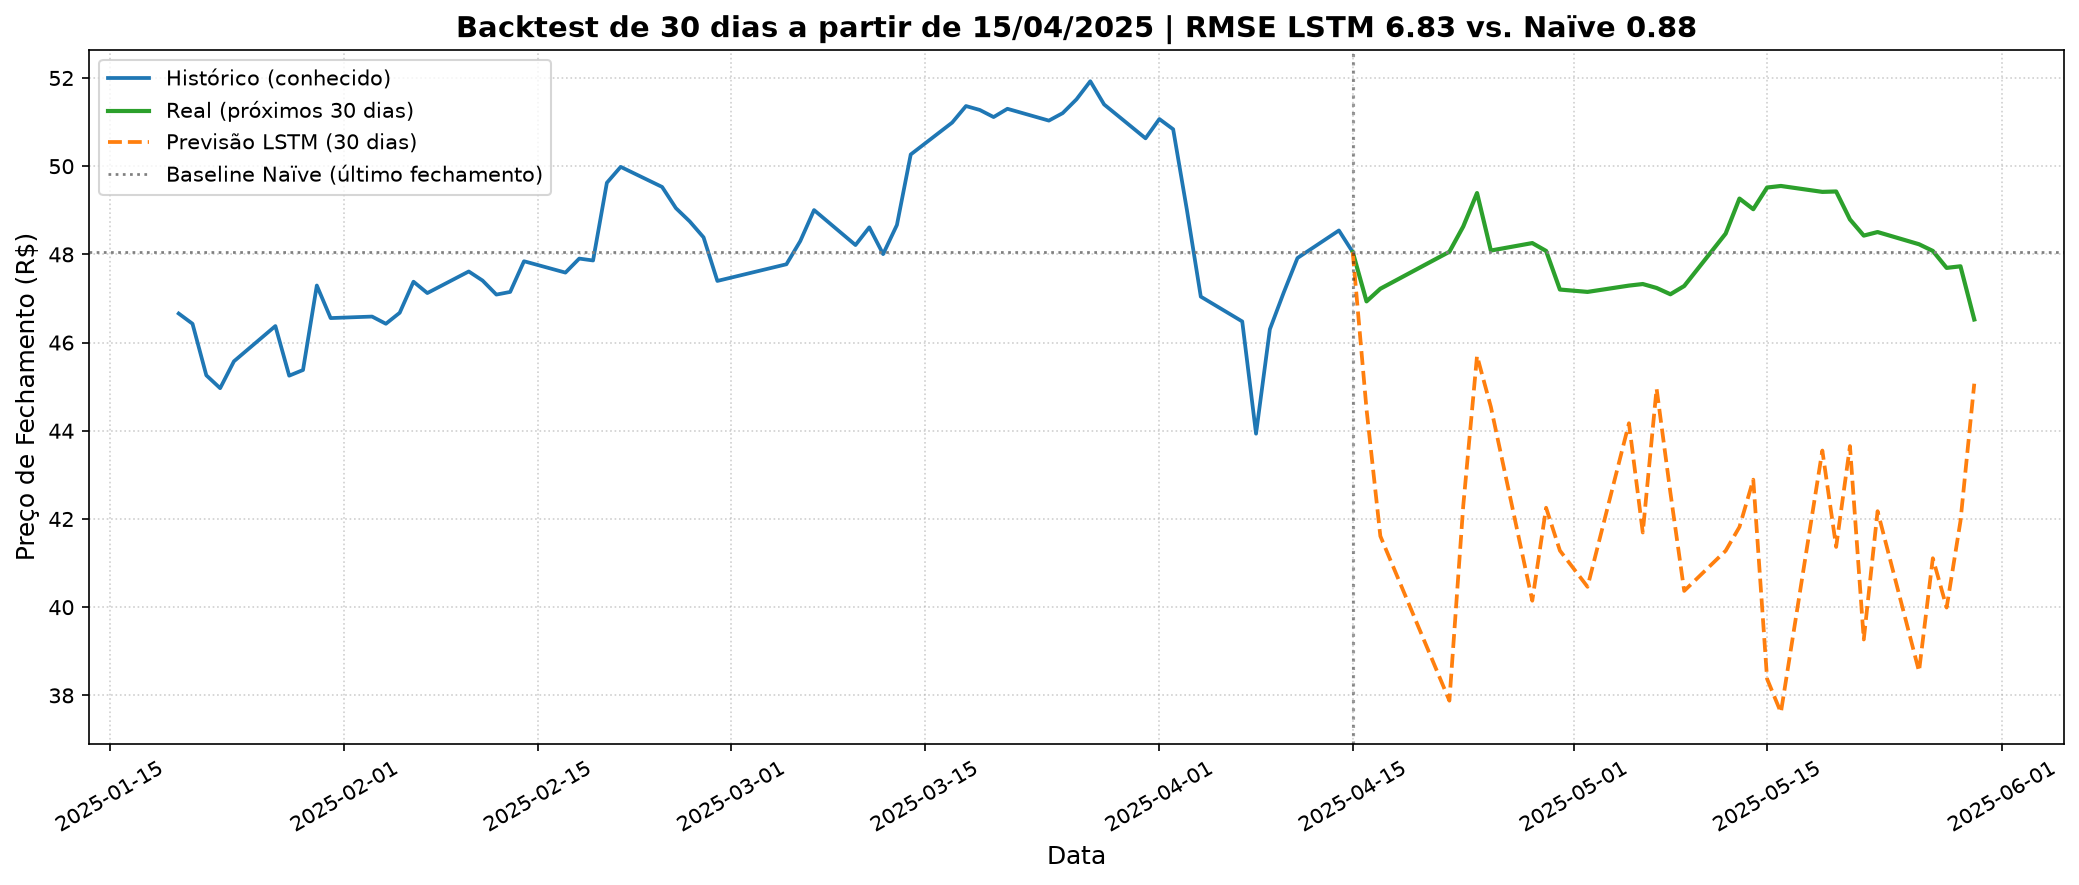

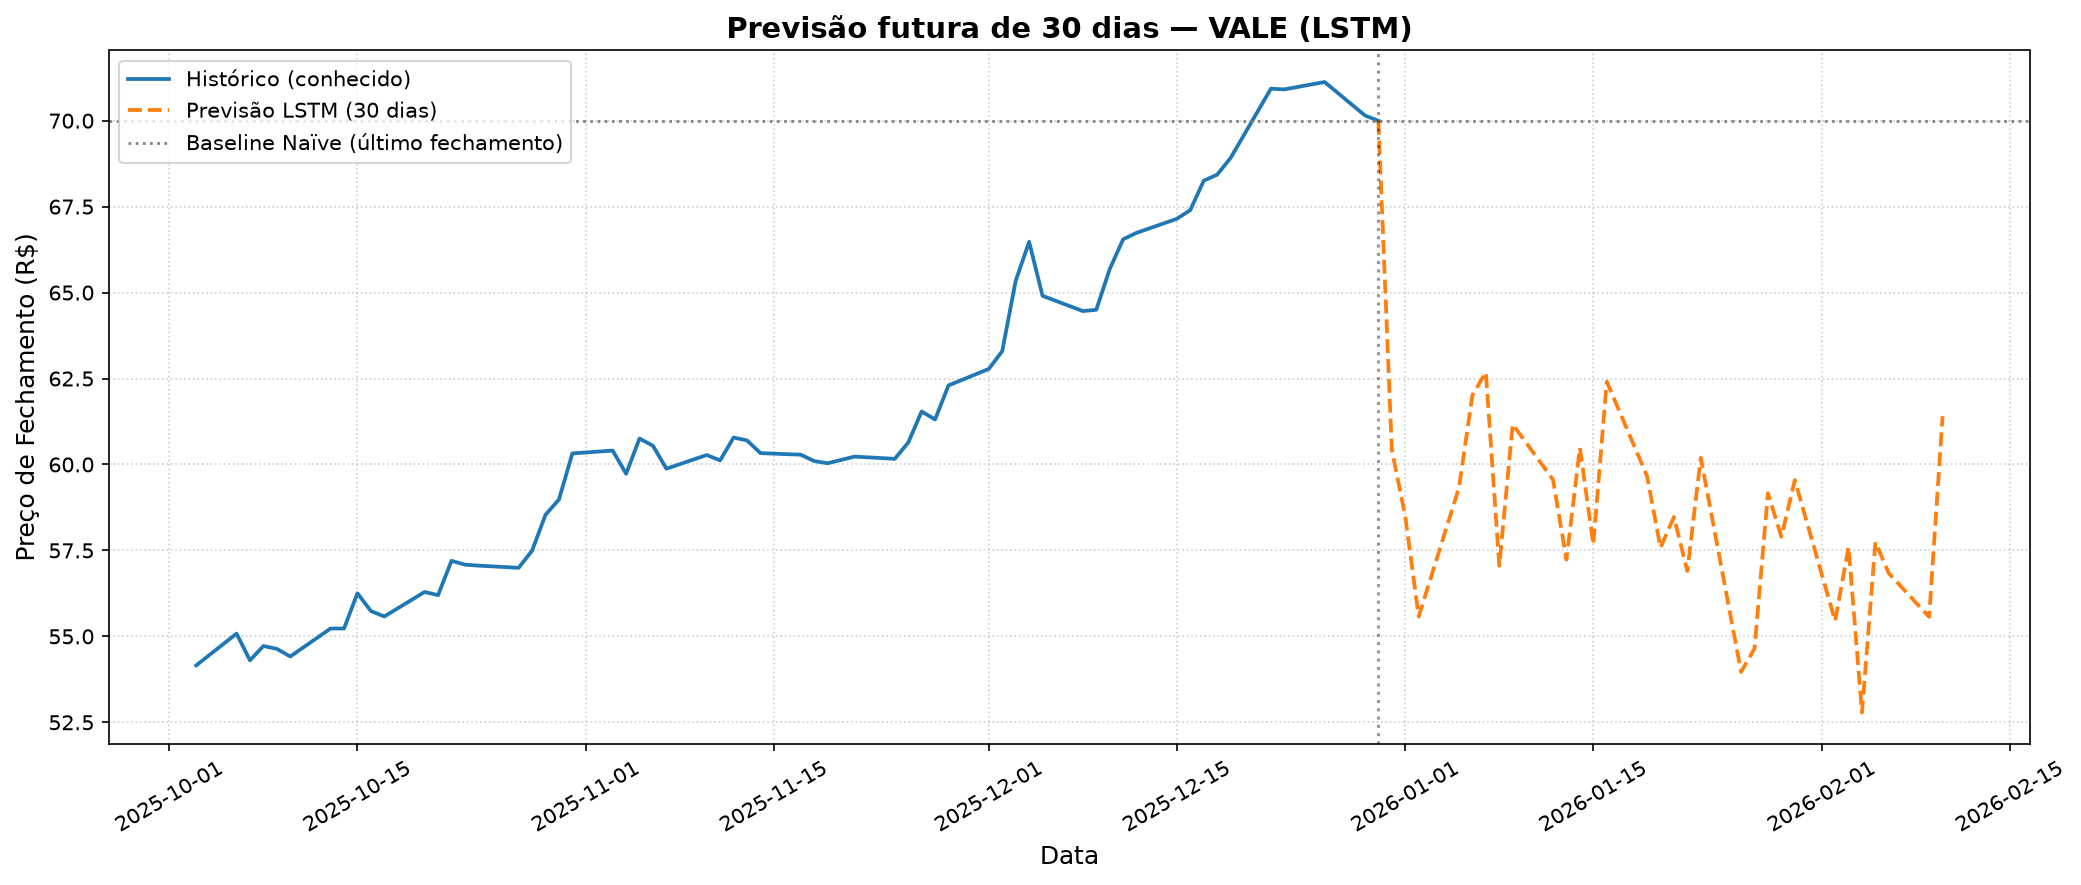

In [10]:
res_30 = run_lstm_30(train_vale, test_vale, "vale", res_lstm["best_params"])

res_30["metricas"]                       # RMSE / MAE / MAPE por origem, com o RMSE do naive
res_30["metricas"].mean(numeric_only=True)

plot_forecast_30(res_30, train_vale, test_vale, "vale", origem="2025-03-31")   # backtest com preço real
plot_forecast_30(res_30, train_vale, test_vale, "vale")                        # previsão futura

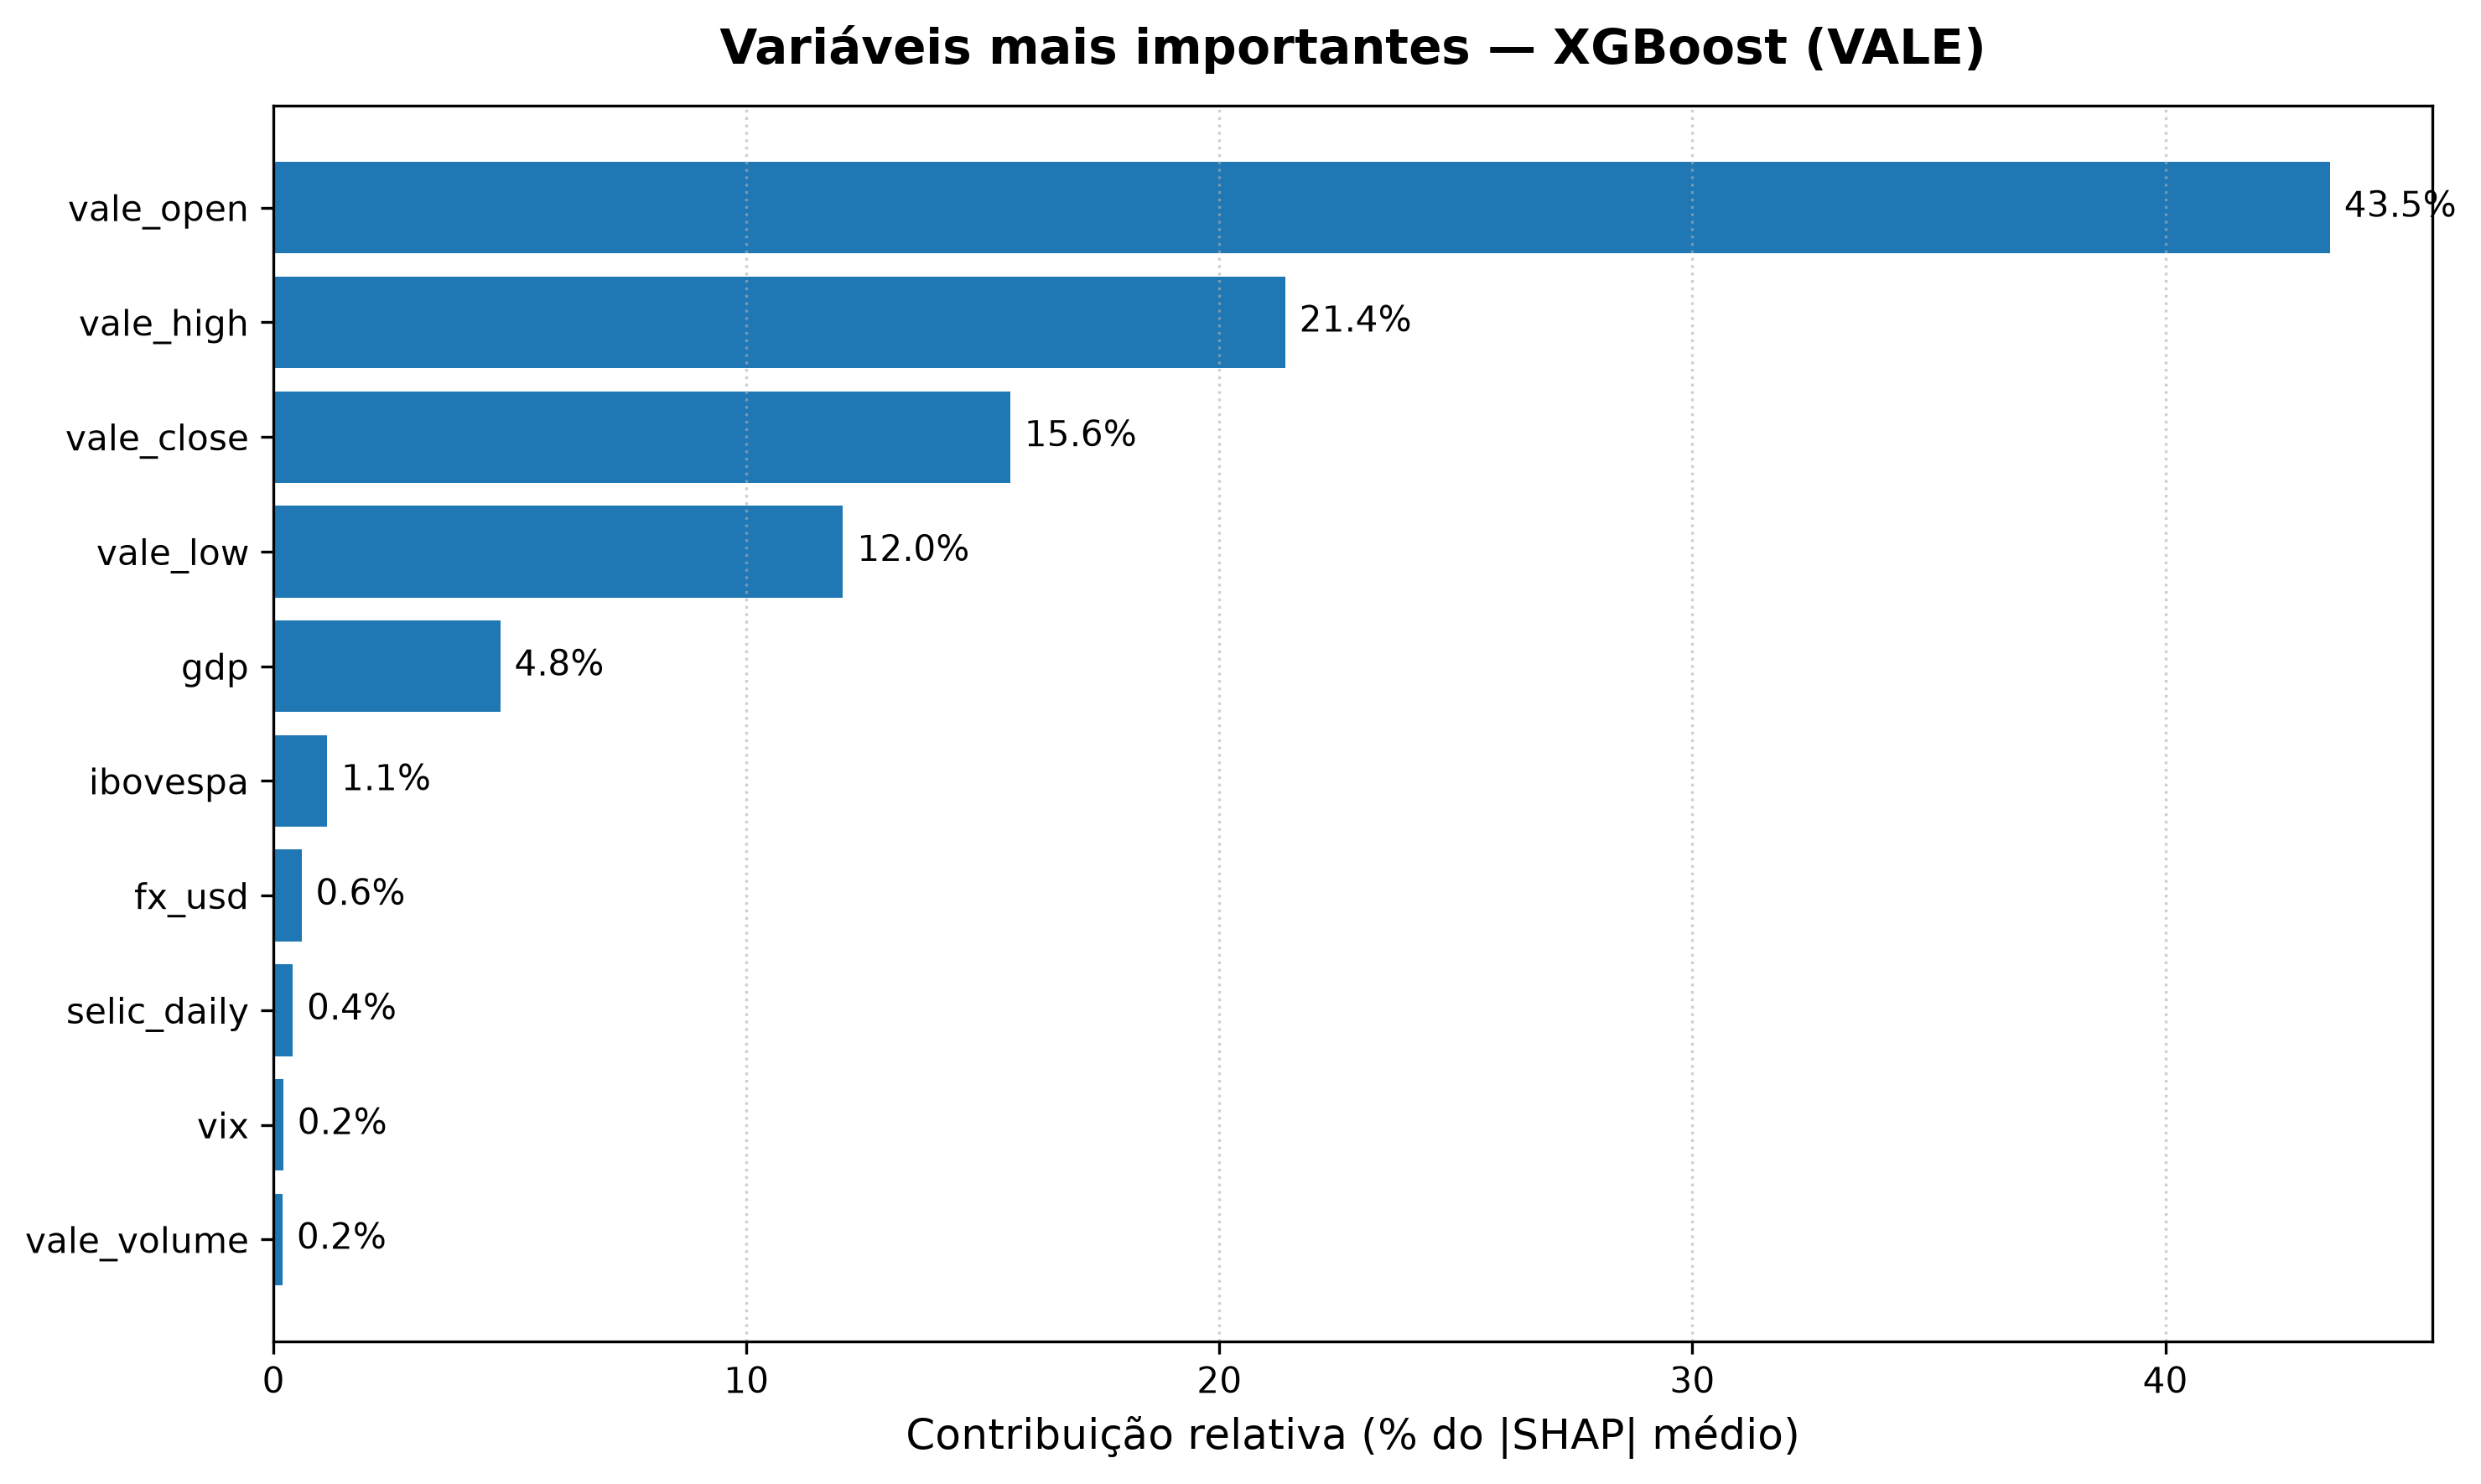

,variavel,mean_abs_shap,pct
0,vale_open,11.662192,43.479462
1,vale_high,5.737247,21.389839
2,vale_close,4.178301,15.577714
3,vale_low,3.229946,12.042019
4,gdp,1.285523,4.792738
5,ibovespa,0.303920,1.133088
6,fx_usd,0.158859,0.592263
7,selic_daily,0.109223,0.407211
8,vix,0.055552,0.207111
9,vale_volume,0.051600,0.192377


In [11]:
tab_vale = explain_variables(res_xgbooster)
tab_vale.head(10)

In [12]:
tab_vale = explain_variables(res_lstm)
tab_vale.head(10)

InvalidModelError: Model type not yet supported by TreeExplainer: <class 'keras.src.models.sequential.Sequential'>